In [1]:
import kagglehub
path = kagglehub.dataset_download("uciml/adult-census-income")

Using Colab cache for faster access to the 'adult-census-income' dataset.


In [2]:
print(path)

/kaggle/input/adult-census-income


In [3]:
import pandas as pd
import sklearn

In [4]:
df= pd.read_csv(r'/kaggle/input/adult-census-income/adult.csv')

In [5]:
df

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [7]:
!pip install fairlearn xgboost

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_openml

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45222 entries, 0 to 45221
Data columns (total 16 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             45222 non-null  int64   
 1   workclass       45222 non-null  category
 2   fnlwgt          45222 non-null  int64   
 3   education       45222 non-null  category
 4   education-num   45222 non-null  int64   
 5   marital-status  45222 non-null  category
 6   occupation      45222 non-null  category
 7   relationship    45222 non-null  category
 8   race            45222 non-null  category
 9   sex             45222 non-null  category
 10  capital-gain    45222 non-null  int64   
 11  capital-loss    45222 non-null  int64   
 12  hours-per-week  45222 non-null  int64   
 13  native-country  45222 non-null  category
 14  income          45222 non-null  category
 15  y               45222 non-null  int64   
dtypes: category(9), int64(7)
memory usage: 2.8 MB


In [9]:
print(df["income"].value_counts())
print(df["income"].value_counts(normalize=True).round(3))

income
<=50K    34014
>50K     11208
Name: count, dtype: int64
income
<=50K    0.752
>50K     0.248
Name: proportion, dtype: float64


In [13]:
df['sex'].value_counts(normalize=True).round(3)


,proportion
sex,
Male,0.675
Female,0.325


In [16]:
pos_rate = df.groupby("sex")["y"].mean().round(3)
print(pos_rate)

sex
Female    0.114
Male      0.312
Name: y, dtype: float64


/tmp/ipykernel_1791/1530090736.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pos_rate = df.groupby("sex")["y"].mean().round(3)


In [14]:
df["y"] = (df["income"] == ">50K").astype(int)
pos_rate = df.groupby("sex")["y"].mean().round(3)
print(pos_rate)
print("Gap (Male - Female):", round(pos_rate["Male"] - pos_rate["Female"], 3))

sex
Female    0.114
Male      0.312
Name: y, dtype: float64
Gap (Male - Female): 0.198


/tmp/ipykernel_1791/1714655231.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  pos_rate = df.groupby("sex")["y"].mean().round(3)


In [21]:
print(df.groupby("race")['y'].agg(["mean", "count"]).round(3))

                     mean  count
race                            
Amer-Indian-Eskimo  0.122    435
Asian-Pac-Islander  0.283   1303
Black               0.126   4228
Other               0.127    353
White               0.262  38903


/tmp/ipykernel_1791/2155816193.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("race")['y'].agg(["mean", "count"]).round(3))


/tmp/ipykernel_1791/3988616003.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["sex", "income"]).size().unstack().plot(kind="bar", ax=axes[2])


IndexError: index 2 is out of bounds for axis 0 with size 2

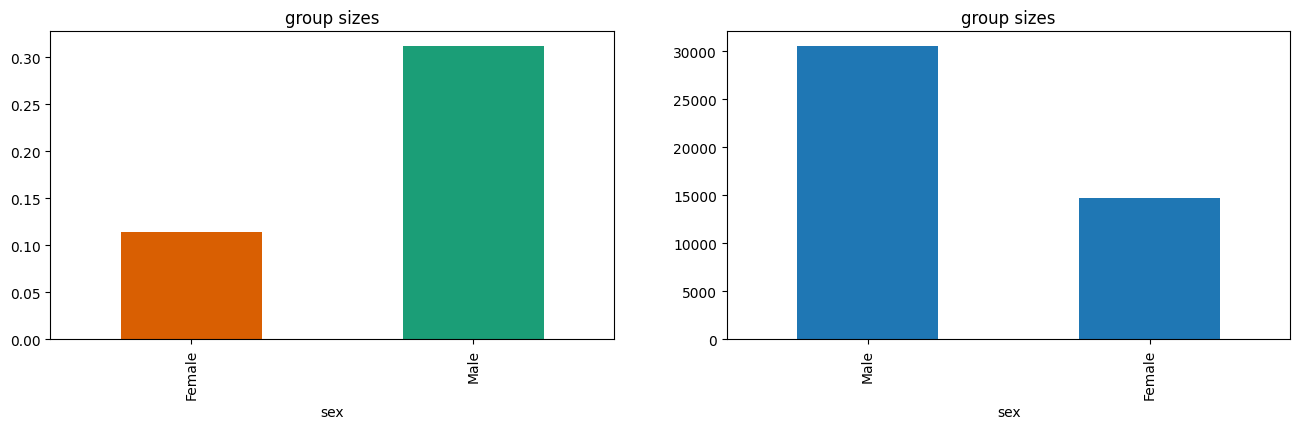

In [24]:
fig, axes= plt.subplots(1,2,figsize=(16,4))

pos_rate.plot(kind='bar',ax= axes[0],color=["#d95f02", "#1b9e77"])
axes[0].set_title("group sizes")

df['sex'].value_counts().plot(kind='bar',ax=axes[1])
axes[1].set_title("group sizes")

df.groupby(["sex", "income"]).size().unstack().plot(kind="bar", ax=axes[2])
axes[2].set_title("Income class by sex")

for ax in axes:
    ax.tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("eda_overview.png", dpi=150)
plt.show()

/tmp/ipykernel_1791/2405710286.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby("sex")[num_cols].mean().round(2))


          age  education-num  hours-per-week  capital-gain  capital-loss
sex                                                                     
Female  36.98          10.11           36.93        588.13         61.48
Male    39.30          10.12           42.87       1348.52        101.65


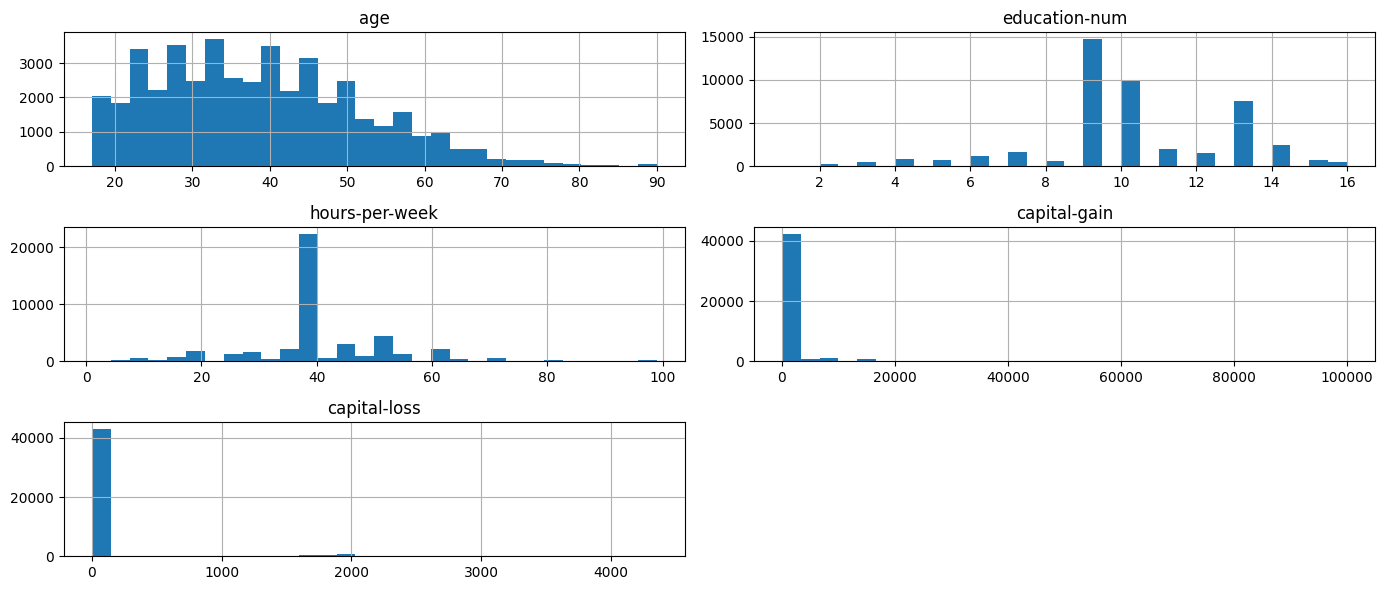

In [25]:
num_cols = ["age", "education-num", "hours-per-week", "capital-gain", "capital-loss"]
print(df.groupby("sex")[num_cols].mean().round(2))

df[num_cols].hist(figsize=(14, 6), bins=30)
plt.tight_layout()
plt.show()

In [26]:
cat_cols = ["workclass", "education", "marital-status", "occupation", "relationship"]
for col in cat_cols:
    print(f"\n{col}: share earning >50K")
    print(df.groupby(col)["y"].mean().sort_values(ascending=False).round(3))


workclass: share earning >50K
workclass
Self-emp-inc        0.554
Federal-gov         0.390
Local-gov           0.295
Self-emp-not-inc    0.279
State-gov           0.267
Private             0.218
Without-pay         0.095
Never-worked          NaN
Name: y, dtype: float64

education: share earning >50K
education
Prof-school     0.754
Doctorate       0.733
Masters         0.554
Bachelors       0.420
Assoc-acdm      0.264
Assoc-voc       0.257
Some-college    0.201
HS-grad         0.163
12th            0.075
10th            0.067
7th-8th         0.067
9th             0.056
11th            0.055
5th-6th         0.049
1st-4th         0.036
Preschool       0.014
Name: y, dtype: float64

marital-status: share earning >50K
marital-status
Married-civ-spouse       0.454
Married-AF-spouse        0.438
Divorced                 0.104
Married-spouse-absent    0.098
Widowed                  0.095
Separated                0.070
Never-married            0.048
Name: y, dtype: float64

occupation: share

/tmp/ipykernel_1791/4123299428.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print(df.groupby(col)["y"].mean().sort_values(ascending=False).round(3))


In [27]:
print(pd.crosstab(df["occupation"], df["sex"], normalize="columns").round(3))

sex                Female   Male
occupation                      
Adm-clerical        0.254  0.059
Armed-Forces        0.000  0.000
Craft-repair        0.021  0.187
Exec-managerial     0.117  0.140
Farming-fishing     0.006  0.045
Handlers-cleaners   0.017  0.059
Machine-op-inspct   0.054  0.071
Other-service       0.180  0.071
Priv-house-serv     0.015  0.000
Prof-specialty      0.150  0.125
Protective-serv     0.008  0.028
Sales               0.131  0.114
Tech-support        0.038  0.028
Transport-moving    0.009  0.072


In [28]:
print(df[num_cols + ["y"]].corr()["y"].drop("y").round(3))

age               0.237
education-num     0.333
hours-per-week    0.227
capital-gain      0.221
capital-loss      0.149
Name: y, dtype: float64


In [29]:
y = df["y"]
A = df["sex"]                           # sensitive attribute, kept separate
X = df.drop(columns=["income", "y"])
X = pd.get_dummies(X, drop_first=True)  # encode categorical columns
print("Feature matrix:", X.shape)

Feature matrix: (45222, 97)


In [30]:
from sklearn.model_selection import train_test_split

X.columns = X.columns.str.replace(r"[\[\]<>]", "_", regex=True)  # avoids XGBoost name errors

X_train, X_test, y_train, y_test, A_train, A_test = train_test_split(
    X, y, A, test_size=0.3, random_state=42, stratify=y
)
print(X_train.shape, X_test.shape)

(31655, 97) (13567, 97)


In [55]:
!pip install lightgbm

In [56]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from fairlearn.metrics import demographic_parity_difference, equalized_odds_difference
from fairlearn.postprocessing import ThresholdOptimizer

def evaluate(name, y_true, pred, A_te, seed):
    return {
        "seed": seed,
        "model": name,
        "accuracy": accuracy_score(y_true, pred),
        "dp_gap": demographic_parity_difference(y_true, pred, sensitive_features=A_te),
        "eo_gap": equalized_odds_difference(y_true, pred, sensitive_features=A_te),
    }

all_runs = []
for seed in range(5):
    Xtr, Xte, ytr, yte, Atr, Ate = train_test_split(
        X, y, A, test_size=0.3, random_state=seed, stratify=y
    )

    models = {
        "LogReg": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
        "DecisionTree": DecisionTreeClassifier(max_depth=8, random_state=seed),
        "RandomForest": RandomForestClassifier(n_estimators=200, random_state=seed, n_jobs=-1),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="logloss", random_state=seed),
        "LightGBM": LGBMClassifier(n_estimators=200, random_state=seed, verbose=-1),
        "HistGB": HistGradientBoostingClassifier(random_state=seed),
        "MLP": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=seed)),
    }

    for name, model in models.items():
        # baseline
        model.fit(Xtr, ytr)
        all_runs.append(evaluate(name, yte, model.predict(Xte), Ate, seed))

        # mitigation (now inside the loop, so every model gets it)
        mitigator = ThresholdOptimizer(
            estimator=model,
            constraints="equalized_odds",
            prefit=True,
            predict_method="predict_proba",
        )
        mitigator.fit(Xtr, ytr, sensitive_features=Atr)
        pred_fair = mitigator.predict(Xte, sensitive_features=Ate, random_state=seed)
        all_runs.append(evaluate(name + " + ThresholdOpt", yte, pred_fair, Ate, seed))

    print(f"Seed {seed} done")

results = pd.DataFrame(all_runs)
summary = results.groupby("model")[["accuracy", "dp_gap", "eo_gap"]].agg(["mean", "std"]).round(3)
summary

/usr/local/lib/python3.13/dist-packages/fairlearn/postprocessing/_interpolated_thresholder.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00973168 0.81112605 0.00973168 ... 0.00973168 0.81112605 0.00973168]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  positive_probs[sensitive_feature_vector == a] = interpolated_predictions[
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Seed 0 done


/usr/local/lib/python3.13/dist-packages/fairlearn/postprocessing/_interpolated_thresholder.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00913277 0.00913277 0.00913277 ... 0.00913277 0.82274976 0.82274976]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  positive_probs[sensitive_feature_vector == a] = interpolated_predictions[


Seed 1 done


/usr/local/lib/python3.13/dist-packages/fairlearn/postprocessing/_interpolated_thresholder.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00962912 0.00962912 0.00962912 ... 0.00962912 0.00962912 0.00962912]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  positive_probs[sensitive_feature_vector == a] = interpolated_predictions[


Seed 2 done


/usr/local/lib/python3.13/dist-packages/fairlearn/postprocessing/_interpolated_thresholder.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.0090454 0.0090454 0.0090454 ... 0.0090454 0.0090454 0.0090454]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  positive_probs[sensitive_feature_vector == a] = interpolated_predictions[
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Seed 3 done


/usr/local/lib/python3.13/dist-packages/fairlearn/postprocessing/_interpolated_thresholder.py:150: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[0.00856837 0.00856837 0.00856837 ... 0.84056119 0.00856837 0.00856837]' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  positive_probs[sensitive_feature_vector == a] = interpolated_predictions[
/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


Seed 4 done


accuracy        dp_gap        eo_gap       
                                mean    std   mean    std   mean    std
model                                                                  
DecisionTree                   0.853  0.002  0.153  0.009  0.080  0.026
DecisionTree + ThresholdOpt    0.841  0.002  0.094  0.011  0.030  0.023
HistGB                         0.869  0.003  0.182  0.008  0.086  0.018
HistGB + ThresholdOpt          0.857  0.002  0.111  0.010  0.027  0.027
LightGBM                       0.869  0.003  0.182  0.008  0.084  0.018
LightGBM + ThresholdOpt        0.856  0.003  0.123  0.008  0.039  0.026
LogReg                         0.848  0.002  0.185  0.008  0.106  0.021
LogReg + ThresholdOpt          0.831  0.001  0.089  0.009  0.030  0.013
MLP                            0.822  0.004  0.192  0.016  0.101  0.016
MLP + ThresholdOpt             0.814  0.005  0.139  0.006  0.058  0.015
RandomForest                   0.851  0.003  0.187  0.009  0.095  0.021
RandomForest + ThresholdOpt    0.852  0.004  0.171  0.014  0.082  0.034
XGBoost                        0.865  0.002  0.185  0.011  0.083  0.018
XGBoost + ThresholdOpt         0.855  0.002  0.133  0.011  0.031  0.015

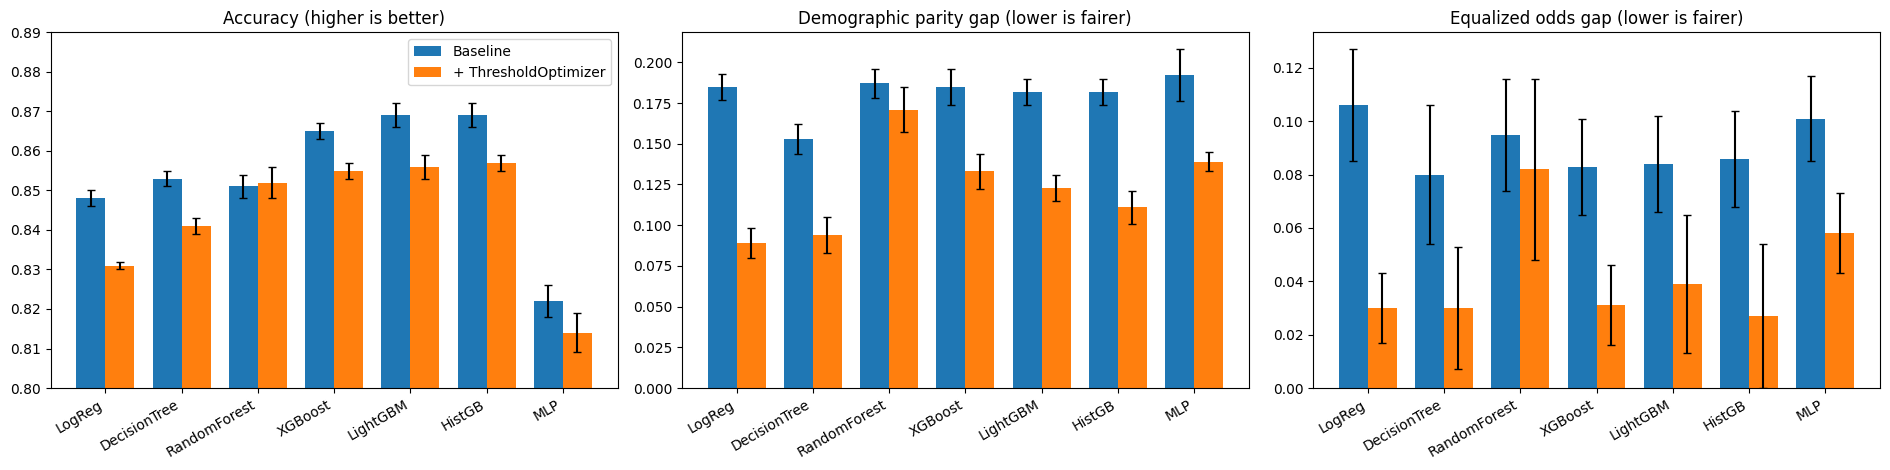

In [57]:
import numpy as np
import matplotlib.pyplot as plt

models_order = ["LogReg", "DecisionTree", "RandomForest", "XGBoost", "LightGBM", "HistGB", "MLP"]
suffix = " + ThresholdOpt"

base = summary.loc[models_order]
mit = summary.loc[[m + suffix for m in models_order]]

x = np.arange(len(models_order))
w = 0.38
metrics = [
    ("accuracy", "Accuracy (higher is better)"),
    ("dp_gap", "Demographic parity gap (lower is fairer)"),
    ("eo_gap", "Equalized odds gap (lower is fairer)"),
]

fig, axes = plt.subplots(1, 3, figsize=(19, 4.8))
for ax, (col, title) in zip(axes, metrics):
    ax.bar(x - w/2, base[col]["mean"].values, w, yerr=base[col]["std"].values,
           capsize=3, label="Baseline")
    ax.bar(x + w/2, mit[col]["mean"].values, w, yerr=mit[col]["std"].values,
           capsize=3, label="+ ThresholdOptimizer")
    ax.set_xticks(x)
    ax.set_xticklabels(models_order, rotation=30, ha="right")
    ax.set_title(title)
    if col == "accuracy":
        ax.set_ylim(0.80, 0.89)
axes[0].legend()

plt.tight_layout()
plt.savefig("final_results_bars.png", dpi=150)
plt.show()

In [53]:
all_runs

[{'seed': 0,
  'model': 'LogReg',
  'accuracy': 0.8466868135918036,
  'dp_gap': np.float64(0.17885890606360239),
  'eo_gap': 0.09315569109116839},
 {'seed': 0,
  'model': 'RandomForest',
  'accuracy': 0.8466131053291074,
  'dp_gap': np.float64(0.1790838603614346),
  'eo_gap': 0.08196496823923921},
 {'seed': 0,
  'model': 'XGBoost',
  'accuracy': 0.863418589223852,
  'dp_gap': np.float64(0.17344695004210653),
  'eo_gap': 0.06715409603069593},
 {'seed': 0,
  'model': 'XGBoost + ThresholdOptimizer',
  'accuracy': 0.854794722488391,
  'dp_gap': np.float64(0.12038885243535818),
  'eo_gap': 0.027364953809227877},
 {'seed': 1,
  'model': 'LogReg',
  'accuracy': 0.8506670597774011,
  'dp_gap': np.float64(0.19872710090717063),
  'eo_gap': 0.13515406162464982},
 {'seed': 1,
  'model': 'RandomForest',
  'accuracy': 0.8528783076582885,
  'dp_gap': np.float64(0.1927535770107039),
  'eo_gap': 0.09752715315375171},
 {'seed': 1,
  'model': 'XGBoost',
  'accuracy': 0.8673988354094494,
  'dp_gap': np.fl